# Actividad — Repaso de medio curso e informe comparativo de modelos de regresión
**Aprendizaje Supervisado · Sesión 7 · Árboles de decisión para regresión y evaluación de modelos**

**Qué haremos.** En la presentación vimos el algoritmo **CART**, la **poda** (`max_depth`, `min_samples_leaf`), la **validación cruzada**
(de $k$ pliegues, estratificada y anidada) y el **análisis sesgo–varianza**. Hoy lo juntas todo en un **informe comparativo** de los siete
modelos de regresión del Módulo 2 (lineal, polinomial, Ridge, Lasso, Elastic Net, SVR y árbol) sobre un conjunto de **precios de viviendas simulado**:
¿qué modelo predice mejor, qué tan fiable es esa conclusión y por qué (en términos de sesgo y varianza)?

| Parte | Pregunta que responde | Tema de la presentación |
|---|---|---|
| 0 | ¿Qué datos tenemos y cómo vamos a evaluar? | — |
| 1 | ¿Cómo es un árbol y cuánto memoriza si no lo frenamos? | A1, A8, B1 |
| 2 | ¿Cómo elige CART el mejor corte? | A3–A6 |
| 3 | ¿Cómo se poda con validación? | B2–B6 |
| 4 | ¿Cuánto mejora la validación cruzada a una sola división? ¿Qué $k$ y qué estratificación? | C1–C6 |
| 5 | ¿Cuánto optimismo hay al elegir y evaluar con los mismos datos? | C7–C10 |
| 6 | ¿Cómo se comparan los siete modelos con rigor? | D8 |
| 7 | ¿Por qué rinde así cada modelo? (sesgo y varianza) | D1–D7 |
| 8 | Recomendación final | — |
| 9 | Reto (bonificación) | B7 |

**Tiempo estimado:** 75–90 minutos de trabajo individual.

**Entregable:** este notebook ejecutado (con tus respuestas en las celdas ✏️) y el archivo `entregable_unidad7.csv`
con la tabla *modelo · hiperparámetros · RMSE (CV anidada) · RMSE de entrenamiento · RMSE de prueba · diagnóstico · comentario* de la Parte 6.

**Cómo trabajar.** Ejecuta las celdas en orden. Donde dice ✏️ hay una línea de código por completar o una pregunta;
escribe tus respuestas en la celda de texto que sigue, bajo «**Respuesta:**».
Los datos son **simulados**: como conocemos la función verdadera, en la Parte 7 podemos **medir** el sesgo y la varianza de cada modelo.

> ⚠️ **Regla de oro:** el conjunto de **prueba** (`Xte`, `yte`) se usa **una sola vez**, al final de la Parte 6. Todo lo demás (elegir hiperparámetros, comparar modelos) se hace con **validación cruzada** sobre el entrenamiento.

**Estudiante:** Julian Emiliano Ortiz Rivero

## Parte 0 — Los datos

Cada fila es una vivienda. El precio (en **cientos de miles** de pesos) depende de forma **no lineal** de la superficie, la antigüedad y la distancia al centro (hay un efecto fuerte de «casa nueva» por debajo de 8 años y una curva ondulada con la superficie). `habitaciones` es casi una copia de la superficie (correlación ≈ 0.9) y las tres columnas `ruido_*` **no afectan** al precio. A cada precio se le suma ruido de desviación **0.25**, de modo que **ningún modelo puede tener RMSE menor que 0.25**.

In [1]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV, cross_val_score,
                                     train_test_split, learning_curve)

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SIGMA = 0.25   # ruido irreducible (piso del RMSE)

def verdad(d):
    # La función verdadera SIN ruido (solo la usaremos en la Parte 7)
    return (0.6 + 0.016 * d.superficie * (1 - 0.25 * d.distancia / 25) + 1.5 * np.exp(-d.distancia / 5)
            - 0.022 * d.antiguedad + 0.8 * (d.antiguedad < 8) + 0.45 * np.sin(d.superficie / 20))

def genera(n, semilla):
    rng = np.random.default_rng(semilla)
    d = pd.DataFrame({"superficie": rng.uniform(40, 250, n),
                      "antiguedad": rng.uniform(0, 40, n),
                      "distancia": rng.uniform(0.5, 25, n)})
    d["habitaciones"] = np.clip(np.round(d.superficie / 45 + rng.normal(0, 0.6, n)), 1, 7)
    for j in (1, 2, 3):
        d[f"ruido_{j}"] = rng.standard_normal(n)
    y = verdad(d) + SIGMA * rng.standard_normal(n)
    return d, y

def rmse(modelo, X, y):
    return float(np.mean((y - modelo.predict(X)) ** 2) ** 0.5)

Xtr, ytr = genera(400, semilla=7)       # entrenamiento: 400 viviendas
Xte, yte = genera(3000, semilla=99)     # prueba: NO SE TOCA hasta el final de la Parte 6
kf = KFold(5, shuffle=True, random_state=0)   # protocolo de validación que usaremos SIEMPRE
SCORE = "neg_root_mean_squared_error"          # recuerda: scikit-learn maximiza, por eso el RMSE sale negativo

print("Entrenamiento:", Xtr.shape, "  Prueba:", Xte.shape)
print(Xtr.describe().round(2).T[["mean", "std", "min", "max"]])
print("Precio medio:", round(ytr.mean(), 2), "  desviación:", round(ytr.std(), 2), "  piso de RMSE:", SIGMA)

Entrenamiento: (400, 7)   Prueba: (3000, 7)
                mean    std    min     max
superficie    145.88  61.45  40.78  249.32
antiguedad     19.67  11.09   0.13   39.96
distancia      12.51   7.29   0.60   24.93
habitaciones    3.28   1.53   1.00    7.00
ruido_1        -0.04   0.96  -2.38    2.28
ruido_2         0.00   1.03  -3.66    2.83
ruido_3         0.01   0.99  -2.99    3.15
Precio medio: 2.6   desviación: 1.13   piso de RMSE: 0.25


## Parte 1 — Un árbol de regresión  *(presentación A1, A8, B1)*

Ajustamos un árbol de profundidad 3 y lo leemos como un conjunto de reglas. Después dejamos crecer otro **sin límites** y comparamos el error de entrenamiento con el de **validación cruzada** (todavía no tocamos la prueba).

In [2]:
arbol3 = DecisionTreeRegressor(max_depth=3, random_state=0).fit(Xtr, ytr)
print(export_text(arbol3, feature_names=list(Xtr.columns), decimals=1))

arbol_libre = DecisionTreeRegressor(random_state=0).fit(Xtr, ytr)
cv_libre = -cross_val_score(DecisionTreeRegressor(random_state=0), Xtr, ytr, cv=kf, scoring=SCORE).mean()
print(f"Árbol libre: profundidad {arbol_libre.get_depth()}, hojas {arbol_libre.get_n_leaves()}")
print(f"  RMSE entrenamiento = {rmse(arbol_libre, Xtr, ytr):.3f}    RMSE validación cruzada = {cv_libre:.3f}    piso = {SIGMA}")

|--- superficie <= 121.4
|   |--- antiguedad <= 8.1
|   |   |--- distancia <= 6.6
|   |   |   |--- value: [3.1]
|   |   |--- distancia >  6.6
|   |   |   |--- value: [2.3]
|   |--- antiguedad >  8.1
|   |   |--- distancia <= 4.6
|   |   |   |--- value: [2.0]
|   |   |--- distancia >  4.6
|   |   |   |--- value: [1.2]
|--- superficie >  121.4
|   |--- antiguedad <= 18.3
|   |   |--- distancia <= 10.3
|   |   |   |--- value: [4.2]
|   |   |--- distancia >  10.3
|   |   |   |--- value: [3.4]
|   |--- antiguedad >  18.3
|   |   |--- distancia <= 7.9
|   |   |   |--- value: [3.4]
|   |   |--- distancia >  7.9
|   |   |   |--- value: [2.5]

Árbol libre: profundidad 16, hojas 400
  RMSE entrenamiento = 0.000    RMSE validación cruzada = 0.492    piso = 0.25


✏️ **Pregunta 1.1.** (a) ¿Qué variable y qué valor usa el árbol de profundidad 3 en la raíz? ¿Qué predice una hoja? (b) ¿Cuántas hojas tiene el árbol libre y qué error de entrenamiento obtiene? (c) Compara con su error de validación cruzada: ¿es sesgo alto o varianza alta?

**Respuesta:** La raíz usa `superficie` con un corte de 121.4. Cada hoja predice el promedio de los precios que llegan a ella. El árbol libre tiene 400 hojas, profundidad 16 y RMSE de entrenamiento igual a 0. Su RMSE de validación es 0.492. La brecha muestra varianza alta porque memorizó el entrenamiento.

## Parte 2 — Cómo elige CART un corte  *(presentación A3–A6)*

Implementamos a mano la idea central: para cada variable, probamos todos los cortes posibles y nos quedamos con el de **menor MSE ponderado**.

In [3]:
def mse_nodo(y):
    # impureza de un nodo = varianza de los y alrededor de su promedio
    return np.mean((y - y.mean()) ** 2)

def mse_ponderado(y_izq, y_der):
    n_i, n_d = len(y_izq), len(y_der)
    return (n_i * mse_nodo(y_izq) + n_d * mse_nodo(y_der)) / (n_i + n_d)

def mejor_corte(x, y):
    x = np.asarray(x); y = np.asarray(y)
    vals = np.unique(x)
    mejor = (None, np.inf)
    for c in (vals[:-1] + vals[1:]) / 2:                # puntos medios entre valores consecutivos
        m = mse_ponderado(y[x <= c], y[x > c])
        if m < mejor[1]:
            mejor = (c, m)
    return mejor

raiz = mse_nodo(ytr.values)
filas = []
for col in Xtr.columns:
    c, m = mejor_corte(Xtr[col], ytr)
    filas.append({"variable": col, "mejor_corte": round(c, 2), "mse_ponderado": round(m, 4), "reduccion": round(raiz - m, 4)})
tabla_cortes = pd.DataFrame(filas).sort_values("mse_ponderado").reset_index(drop=True)
print(f"MSE de la raíz (sin cortar): {raiz:.4f}")
print(tabla_cortes.to_string(index=False))

var_sk = Xtr.columns[arbol3.tree_.feature[0]]
print(f"\nscikit-learn parte en la raíz por «{var_sk}» con corte {arbol3.tree_.threshold[0]:.2f}")

MSE de la raíz (sin cortar): 1.2650
    variable  mejor_corte  mse_ponderado  reduccion
  superficie       121.37         0.5977     0.6673
habitaciones         2.50         0.7561     0.5089
   distancia         8.70         1.0966     0.1683
  antiguedad         8.09         1.1014     0.1636
     ruido_1        -2.35         1.2399     0.0250
     ruido_3        -1.43         1.2529     0.0121
     ruido_2        -3.13         1.2592     0.0058

scikit-learn parte en la raíz por «superficie» con corte 121.37


✏️ **Pregunta 2.1.** (a) ¿Qué variable gana el primer corte y cuánto baja el MSE respecto a la raíz? ¿Coincide con scikit-learn? (b) ¿Por qué las variables `ruido_*` quedan al final de la tabla? (c) `superficie` y `habitaciones` son casi iguales: ¿qué esperas de sus MSE y por qué gana una sola?

**Respuesta:** Gana `superficie`. Reduce el MSE de 1.2650 a 0.5977, una baja de 0.6673. Coincide con el corte de `scikit-learn` en 121.37. Las variables de ruido quedan al final porque no guardan una relación estable con el precio. `superficie` y `habitaciones` tienen MSE parecidos por su correlación. Gana una sola porque CART conserva el corte con la reducción mayor.

## Parte 3 — Poda con validación  *(presentación B2–B6)*

Primero la curva de **`max_depth`** (entrenamiento frente a validación cruzada) y después una malla conjunta con `min_samples_leaf`.

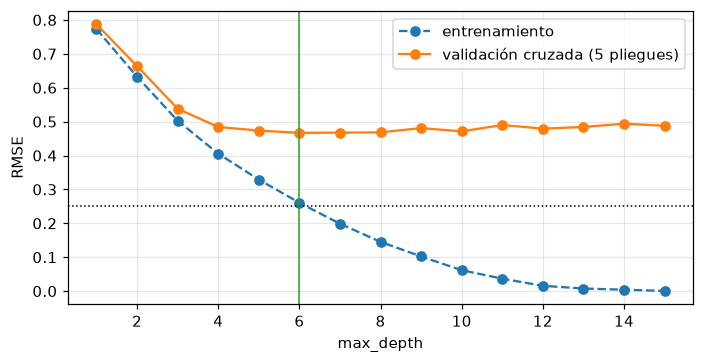

Mejor max_depth por validación: 6   (RMSE de validación = 0.467)


In [4]:
profs = list(range(1, 16))
tr_rm, cv_rm = [], []
for d in profs:
    arb = DecisionTreeRegressor(max_depth=d, random_state=0)
    cv_rm.append(-cross_val_score(arb, Xtr, ytr, cv=kf, scoring=SCORE).mean())
    tr_rm.append(rmse(arb.fit(Xtr, ytr), Xtr, ytr))
mejor_prof = profs[int(np.argmin(cv_rm))]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(profs, tr_rm, "o--", label="entrenamiento"); ax.plot(profs, cv_rm, "o-", label="validación cruzada (5 pliegues)")
ax.axhline(SIGMA, color="k", ls=":", lw=1); ax.axvline(mejor_prof, color="C2", lw=1)
ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Mejor max_depth por validación: {mejor_prof}   (RMSE de validación = {min(cv_rm):.3f})")

param_min_samples_leaf     1      2      5      10     20     40
param_max_depth                                                 
2.0                     0.664  0.664  0.664  0.664  0.664  0.685
3.0                     0.538  0.538  0.538  0.543  0.550  0.581
4.0                     0.484  0.486  0.477  0.490  0.504  0.578
5.0                     0.474  0.474  0.457  0.466  0.494  0.578
6.0                     0.467  0.468  0.451  0.456  0.494  0.578
8.0                     0.468  0.471  0.451  0.455  0.494  0.578
NaN                     0.492  0.482  0.452  0.455  0.494  0.578

Mejores hiperparámetros: {'max_depth': 8, 'min_samples_leaf': 5}    RMSE de validación = 0.451


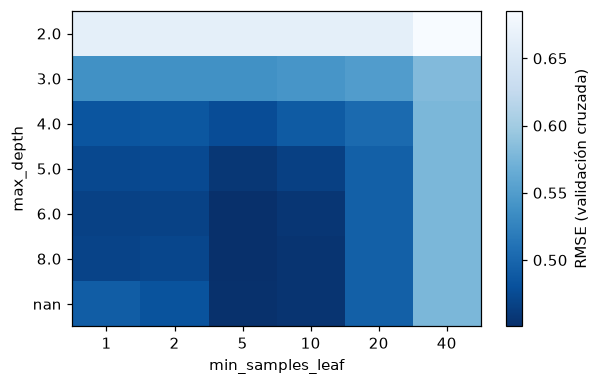

In [5]:
malla_arbol = {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 2, 5, 10, 20, 40]}
busq_arbol = GridSearchCV(DecisionTreeRegressor(random_state=0), malla_arbol, cv=kf, scoring=SCORE, n_jobs=1).fit(Xtr, ytr)

res = pd.DataFrame(busq_arbol.cv_results_)
res["rmse_cv"] = -res["mean_test_score"]
tabla = res.pivot_table(index="param_max_depth", columns="param_min_samples_leaf", values="rmse_cv", dropna=False)
print(tabla.round(3).to_string())
print("\nMejores hiperparámetros:", busq_arbol.best_params_, "   RMSE de validación =", round(-busq_arbol.best_score_, 3))

fig, ax = plt.subplots(figsize=(5.6, 3.6))
im = ax.imshow(tabla.values.astype(float), cmap="Blues_r", aspect="auto"); ax.grid(False)
ax.set_xticks(range(tabla.shape[1])); ax.set_xticklabels(tabla.columns); ax.set_yticks(range(tabla.shape[0])); ax.set_yticklabels([str(i) for i in tabla.index])
ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("max_depth"); plt.colorbar(im, label="RMSE (validación cruzada)"); plt.tight_layout(); plt.show()

✏️ **Pregunta 3.1.** (a) ¿En qué profundidad se minimiza el error de validación y qué pasa con el de entrenamiento al seguir creciendo? (b) ¿Qué combinación eligió `GridSearchCV` y qué tan cerca del piso de 0.25 queda? (c) ¿La zona de buenos valores es estrecha o amplia? ¿Qué implica para afinar los hiperparámetros?

**Respuesta:** El menor RMSE aparece con profundidad 8 y cinco observaciones por hoja: 0.451. Al aumentar la profundidad, el error de entrenamiento sigue bajando aunque la validación ya no mejora. El resultado queda 0.201 arriba del piso de 0.25. Hay varias combinaciones entre 0.451 y 0.468, así que la zona buena es amplia y no hace falta afinar con una malla demasiado estrecha.

## Parte 4 — Validación cruzada: una división, $k$ pliegues y estratificación  *(presentación C1–C6)*

**4a.** Repetimos 100 veces una división 80/20 con otra semilla y comparamos con validación cruzada de 5 pliegues repetida con otras 20 semillas (mismo árbol podado).

1 división 80/20  : mínimo 0.349  máximo 0.581  desviación 0.045
CV de 5 pliegues  : mínimo 0.429  máximo 0.475  desviación 0.012


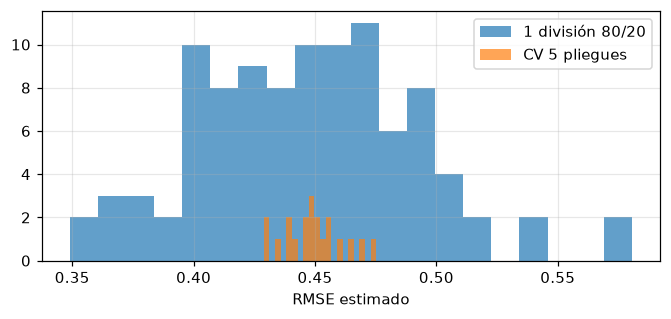

In [6]:
arbol_p = DecisionTreeRegressor(**busq_arbol.best_params_, random_state=0)

ho = []
for s in range(100):
    a, b, c, d = train_test_split(Xtr, ytr, test_size=0.2, random_state=s)
    ho.append(rmse(arbol_p.fit(a, c), b, d))

cvs = []
for s in range(20):
    cvs.append(-cross_val_score(arbol_p, Xtr, ytr, cv=KFold(5, shuffle=True, random_state=s), scoring=SCORE, n_jobs=1).mean())

print(f"1 división 80/20  : mínimo {min(ho):.3f}  máximo {max(ho):.3f}  desviación {np.std(ho):.3f}")
print(f"CV de 5 pliegues  : mínimo {min(cvs):.3f}  máximo {max(cvs):.3f}  desviación {np.std(cvs):.3f}")
fig, ax = plt.subplots(figsize=(6.2, 3))
ax.hist(ho, bins=20, alpha=.7, label="1 división 80/20"); ax.hist(cvs, bins=20, alpha=.7, label="CV 5 pliegues")
ax.set_xlabel("RMSE estimado"); ax.legend(); plt.tight_layout(); plt.show()

**4b. ¿Cuántos pliegues?** Medimos el RMSE estimado y el número de ajustes para distintos $k$ (misma semilla de barajado).

In [7]:
filas = []
for k in [2, 3, 5, 10, 20]:
    t0 = time.time()
    p = -cross_val_score(arbol_p, Xtr, ytr, cv=KFold(k, shuffle=True, random_state=0), scoring=SCORE)
    filas.append({"k": k, "RMSE_medio": p.mean(), "desviacion_entre_pliegues": p.std(), "ajustes": k, "segundos": time.time() - t0})
tabla_k = pd.DataFrame(filas).set_index("k")
print(tabla_k.round(3).to_string())

    RMSE_medio  desviacion_entre_pliegues  ajustes  segundos
k                                                           
2        0.494                      0.036        2     0.008
3        0.475                      0.060        3     0.010
5        0.451                      0.025        5     0.015
10       0.414                      0.051       10     0.030
20       0.430                      0.073       20     0.064


**4c. Estratificación en regresión.** El precio no tiene clases, así que **estratificamos por cuantiles** de $y$. Comparamos cuánto varía el precio promedio entre pliegues con `KFold` y con `StratifiedKFold` (200 barajados distintos). Después, el caso clásico: una clase rara.

In [8]:
grupos = pd.qcut(ytr, q=5, labels=False)          # 5 grupos de precio con igual número de casas
sd_kfold, sd_estrat = [], []
for s in range(200):
    medias_k = [ytr.values[v].mean() for _, v in KFold(5, shuffle=True, random_state=s).split(Xtr)]
    skf = StratifiedKFold(5, shuffle=True, random_state=s)
    medias_s = [ytr.values[v].mean() for _, v in skf.split(Xtr, grupos)]
    sd_kfold.append(np.std(medias_k)); sd_estrat.append(np.std(medias_s))
print(f"Dispersión del precio medio entre pliegues:  KFold = {np.mean(sd_kfold):.4f}   StratifiedKFold = {np.mean(sd_estrat):.4f}")

# Caso clásico: la clase rara (el 5 % de las casas más caras)
rara = (ytr > ytr.quantile(0.95)).astype(int).values
print("\nCasas «raras» por pliegue (total:", rara.sum(), ")")
print("  KFold          :", [int(rara[v].sum()) for _, v in KFold(5, shuffle=True, random_state=1).split(Xtr)])
print("  StratifiedKFold:", [int(rara[v].sum()) for _, v in StratifiedKFold(5, shuffle=True, random_state=1).split(Xtr, rara)])

Dispersión del precio medio entre pliegues:  KFold = 0.1102   StratifiedKFold = 0.0262

Casas «raras» por pliegue (total: 20 )
  KFold          : [5, 3, 4, 3, 5]
  StratifiedKFold: [4, 4, 4, 4, 4]


✏️ **Pregunta 4.1.** (a) ¿Qué tanto varía el RMSE con una sola división frente a la validación cruzada? ¿Qué te dice sobre confiar en una división? (b) En la tabla de $k$, ¿qué ocurre con el RMSE medio al subir $k$ y por qué $k=2$ es más pesimista? ¿Qué $k$ recomiendas y por qué? (c) ¿Qué ganó la estratificación en regresión y en el caso de la clase rara?

**Respuesta:** Con una división el RMSE va de 0.349 a 0.581 y su desviación es 0.045. Con cinco pliegues va de 0.429 a 0.475 y la desviación baja a 0.012. Una sola partición depende demasiado de qué datos caigan en validación. Con k=2 el RMSE es 0.494 porque cada ajuste usa solo la mitad de los datos. Recomiendo k=5 por estabilidad y costo. La estratificación baja la dispersión de los promedios de 0.1102 a 0.0262. También reparte los 20 casos raros en cuatro por pliegue.

## Parte 5 — Validación cruzada anidada  *(presentación C7–C10)*

Elegir hiperparámetros con validación cruzada y reportar **esa misma puntuación** es optimista. La validación **anidada** evalúa *todo el procedimiento* (búsqueda incluida) en datos que la búsqueda no vio.

In [9]:
interno = KFold(5, shuffle=True, random_state=1)
externo = KFold(5, shuffle=True, random_state=2)
busq = GridSearchCV(DecisionTreeRegressor(random_state=0), malla_arbol, cv=interno, scoring=SCORE)

simple = -busq.fit(Xtr, ytr).best_score_                                  # lo que reporta GridSearchCV
anidada = -cross_val_score(busq, Xtr, ytr, cv=externo, scoring=SCORE, n_jobs=1)
print(f"CV simple (la mejor combinación): {simple:.3f}")
print(f"CV anidada: media = {anidada.mean():.3f}   desviación = {anidada.std():.3f}   por pliegue = {np.round(anidada, 3)}")
print(f"Ajustes de la anidada: {5 * (5 * len(busq.cv_results_['params']) + 1)}")

CV simple (la mejor combinación): 0.460
CV anidada: media = 0.452   desviación = 0.062   por pliegue = [0.381 0.416 0.435 0.464 0.562]
Ajustes de la anidada: 1055


Con **400** datos la diferencia suele ser pequeña. El optimismo crece cuando hay **pocos datos** y **muchas combinaciones**. Repetimos con submuestras de **60** casas (15 repeticiones). Esta celda ya está completa.

In [10]:
dif = []
for s in range(15):
    sub = np.random.default_rng(100 + s).choice(len(Xtr), 60, replace=False)
    Xs, ys = Xtr.iloc[sub], ytr.iloc[sub]
    g = GridSearchCV(DecisionTreeRegressor(random_state=0), malla_arbol, cv=KFold(5, shuffle=True, random_state=s), scoring=SCORE, n_jobs=1)
    sim = -g.fit(Xs, ys).best_score_
    ani = -cross_val_score(g, Xs, ys, cv=KFold(5, shuffle=True, random_state=s + 50), scoring=SCORE).mean()
    dif.append(ani - sim)
print(f"Con n = 60: la anidada da, en promedio, {np.mean(dif):+.3f} respecto a la simple "
      f"(positivo = la simple era optimista). Fue mayor en {sum(d > 0 for d in dif)} de 15 repeticiones.")

Con n = 60: la anidada da, en promedio, +0.066 respecto a la simple (positivo = la simple era optimista). Fue mayor en 12 de 15 repeticiones.


✏️ **Pregunta 5.1.** (a) Con los 400 datos, ¿cuánto difieren la CV simple y la anidada? (b) Con $n=60$, ¿qué pasa y por qué? (c) Si solo vas a **reportar** un error esperado, ¿cuál usas? ¿Y para escoger los hiperparámetros finales del modelo que vas a entregar?

**Respuesta:** Con 400 observaciones la CV simple da 0.460 y la anidada 0.452 ± 0.062. La diferencia es pequeña. Con 60 datos la anidada queda 0.066 arriba en promedio porque la CV simple reutiliza los resultados que sirvieron para elegir. Para reportar el error esperado usaría la validación anidada. Para escoger los hiperparámetros finales haría una búsqueda sobre todo el entrenamiento.

## Parte 6 — Informe comparativo de los siete modelos  *(presentación D8)*

Todos los modelos son `Pipeline` (el escalado va dentro) con su propia malla. Los modelos de penalización y el polinomial usan variables polinomiales. Comparamos con **validación cruzada anidada** (5 pliegues externos × 3 internos).

> ℹ️ La celda puede tardar un par de minutos.

In [11]:
def con_poly(grado, estimador):
    return make_pipeline(PolynomialFeatures(grado, include_bias=False), StandardScaler(), estimador)

MODELOS = {
    "Lineal":       (make_pipeline(StandardScaler(), LinearRegression()), {}),
    "Polinomial":   (con_poly(2, LinearRegression()), {"polynomialfeatures__degree": [1, 2, 3, 4]}),
    "Ridge":        (con_poly(3, Ridge()), {"ridge__alpha": np.logspace(-2, 3, 6)}),
    "Lasso":        (con_poly(3, Lasso(max_iter=50000)), {"lasso__alpha": np.logspace(-4, -1, 6)}),
    "Elastic Net":  (con_poly(3, ElasticNet(max_iter=50000)), {"elasticnet__alpha": np.logspace(-4, -1, 4), "elasticnet__l1_ratio": [0.2, 0.5, 0.8]}),
    "SVR":          (make_pipeline(StandardScaler(), SVR()), {"svr__C": [10, 100, 1000], "svr__gamma": [0.003, 0.01, 0.05, 0.2], "svr__epsilon": [0.05, 0.2]}),
    "Árbol":        (DecisionTreeRegressor(random_state=0), {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 2, 5, 10, 20, 40]}),
}
ext = KFold(5, shuffle=True, random_state=2)
int3 = KFold(3, shuffle=True, random_state=1)

anidadas = {}
for nombre, (modelo, malla) in MODELOS.items():
    t0 = time.time()
    busqueda = GridSearchCV(modelo, malla, cv=int3, scoring=SCORE, n_jobs=1)
    p = -cross_val_score(busqueda, Xtr, ytr, cv=ext, scoring=SCORE)
    anidadas[nombre] = p
    print(f"{nombre:12s} RMSE (CV anidada) = {p.mean():.3f} ± {p.std():.3f}     [{time.time() - t0:.0f} s]")

Lineal       RMSE (CV anidada) = 0.485 ± 0.020     [0 s]

Polinomial   RMSE (CV anidada) = 0.462 ± 0.034     [0 s]


Ridge        RMSE (CV anidada) = 0.492 ± 0.037     [1 s]


Lasso        RMSE (CV anidada) = 0.468 ± 0.031     [14 s]


Elastic Net  RMSE (CV anidada) = 0.464 ± 0.025     [32 s]


SVR          RMSE (CV anidada) = 0.450 ± 0.020     [9 s]


Árbol        RMSE (CV anidada) = 0.446 ± 0.062     [2 s]


✏️ **Pregunta 6.1.** (a) Ordena los modelos de mejor a peor según la CV anidada. (b) ¿La diferencia entre los dos mejores es mayor que su desviación entre pliegues? ¿Qué concluyes? (c) ¿Qué modelo(s) quedan claramente fuera y a qué se debe?

**Respuesta:** El orden es Árbol, SVR, Polinomial, Elastic Net, Lasso, Lineal y Ridge. Árbol obtiene 0.446 ± 0.062. SVR obtiene 0.450 ± 0.020. La diferencia de 0.004 es menor que la dispersión, por lo que no se puede afirmar que el árbol sea superior. Lineal y Ridge quedan claramente atrás porque no alcanzan el mismo equilibrio para esta relación no lineal.

Ahora entrenamos cada modelo con **todo el entrenamiento** (eligiendo hiperparámetros con validación cruzada de 5 pliegues) y, **por primera y única vez**, miramos el conjunto de **prueba**.

In [12]:
finales = {}
filas = []
for nombre, (modelo, malla) in MODELOS.items():
    g = GridSearchCV(modelo, malla, cv=kf, scoring=SCORE, n_jobs=1).fit(Xtr, ytr)
    finales[nombre] = g.best_estimator_
    filas.append({"modelo": nombre,
                  "hiperparametros": str({k.split("__")[-1]: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in g.best_params_.items()}),
                  "rmse_cv_anidada": round(anidadas[nombre].mean(), 3),
                  "rmse_cv_anidada_sd": round(anidadas[nombre].std(), 3),
                  "rmse_entrenamiento": round(rmse(g.best_estimator_, Xtr, ytr), 3),
                  "rmse_cv": round(-g.best_score_, 3),
                  "rmse_prueba": round(rmse(g.best_estimator_, Xte, yte), 3)})
informe = pd.DataFrame(filas).set_index("modelo").sort_values("rmse_cv_anidada")
print(informe[["rmse_cv_anidada", "rmse_cv_anidada_sd", "rmse_entrenamiento", "rmse_cv", "rmse_prueba"]].to_string())
print(f"\nPiso teórico (ruido) = {SIGMA}")
print(informe["hiperparametros"].to_string())

             rmse_cv_anidada  rmse_cv_anidada_sd  rmse_entrenamiento  rmse_cv  rmse_prueba
modelo                                                                                    
Árbol                  0.446               0.062               0.244    0.451        0.429
SVR                    0.450               0.020               0.386    0.445        0.449
Polinomial             0.462               0.034               0.408    0.456        0.439
Elastic Net            0.464               0.025               0.419    0.459        0.451
Lasso                  0.468               0.031               0.412    0.459        0.447
Lineal                 0.485               0.020               0.476    0.482        0.489
Ridge                  0.492               0.037               0.391    0.488        0.466

Piso teórico (ruido) = 0.25
modelo
Árbol            {'max_depth': 8, 'min_samples_leaf': 5}
SVR            {'C': 100, 'epsilon': 0.2, 'gamma': 0.01}
Polinomial                     

✏️ **Pregunta 6.2.** (a) ¿El orden de la prueba coincide con el de la CV anidada? (b) ¿Qué tan cerca del piso de 0.25 queda el mejor modelo? (c) Compara el RMSE de prueba con el de la CV anidada: ¿la CV anidada fue un estimado honesto? ¿Y el RMSE de entrenamiento?

**Respuesta:** En prueba gana Árbol con 0.429, seguido de Polinomial con 0.439. El orden cambia un poco frente a la CV anidada, donde SVR era segundo. El mejor queda 0.179 arriba del piso de 0.25. El 0.429 de prueba está cerca del 0.446 anidado, por lo que la estimación fue honesta. El 0.244 de entrenamiento del árbol es optimista y muestra la brecha de generalización.

## Parte 7 — ¿Por qué rinde así cada modelo? Sesgo y varianza  *(presentación D1–D7)*

**7a. Diagnóstico por brechas.** Con el RMSE de entrenamiento y el de validación cruzada de cada modelo diagnosticamos si domina el **sesgo** o la **varianza**.

In [13]:
def diagnostico(entren, cv, piso=SIGMA, tol=0.10):
    brecha = cv - entren
    if brecha > tol:
        return "varianza alta"
    if entren > piso + tol:
        return "sesgo alto"
    return "equilibrado"

informe["brecha"] = (informe.rmse_cv - informe.rmse_entrenamiento).round(3)
informe["diagnostico"] = [diagnostico(a, b) for a, b in zip(informe.rmse_entrenamiento, informe.rmse_cv)]
print(informe[["rmse_entrenamiento", "rmse_cv", "brecha", "diagnostico"]].to_string())

             rmse_entrenamiento  rmse_cv  brecha    diagnostico
modelo                                                         
Árbol                     0.244    0.451   0.207  varianza alta
SVR                       0.386    0.445   0.059     sesgo alto
Polinomial                0.408    0.456   0.048     sesgo alto
Elastic Net               0.419    0.459   0.040     sesgo alto
Lasso                     0.412    0.459   0.047     sesgo alto
Lineal                    0.476    0.482   0.006     sesgo alto
Ridge                     0.391    0.488   0.097     sesgo alto


**7b. Medir sesgo y varianza por simulación.** Como conocemos `verdad(...)`, generamos **40 conjuntos de entrenamiento nuevos** (de 400 casas), ajustamos cada modelo (con los hiperparámetros ya elegidos) y comparamos sus predicciones en 500 casas fijas: **sesgo²** = qué tan lejos queda el promedio de las predicciones de la verdad; **varianza** = cuánto se dispersan las predicciones entre conjuntos.

             sesgo2  varianza   ruido   total
modelo                                       
Árbol        0.0219    0.0944  0.0625  0.1788
SVR          0.1108    0.0210  0.0625  0.1943
Polinomial   0.1181    0.0181  0.0625  0.1987
Lasso        0.1283    0.0160  0.0625  0.2069
Elastic Net  0.1320    0.0134  0.0625  0.2078
Ridge        0.1299    0.0340  0.0625  0.2264
Lineal       0.1784    0.0044  0.0625  0.2453


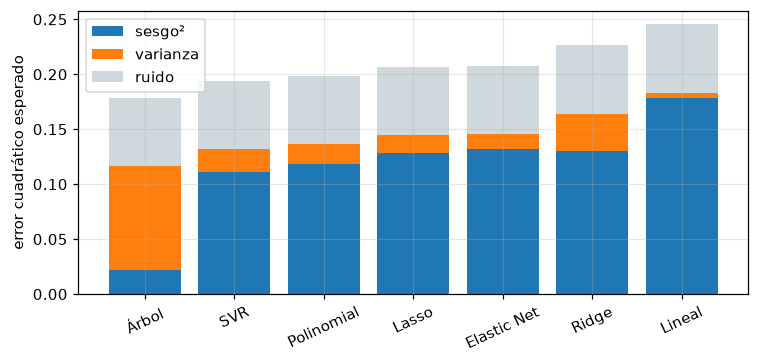

In [14]:
from sklearn.base import clone
Xfija, _ = genera(500, semilla=5)
f_real = verdad(Xfija).values
R = 40
filas = []
for nombre, est in finales.items():
    preds = []
    for r in range(R):
        Xa, ya = genera(400, semilla=1000 + r)
        preds.append(clone(est).fit(Xa, ya).predict(Xfija))
    preds = np.array(preds)                                 # R × 500
    sesgo2 = np.mean((preds.mean(axis=0) - f_real) ** 2)
    varianza = np.mean(preds.var(axis=0))
    filas.append({"modelo": nombre, "sesgo2": sesgo2, "varianza": varianza, "ruido": SIGMA ** 2, "total": sesgo2 + varianza + SIGMA ** 2})
bv = pd.DataFrame(filas).set_index("modelo").sort_values("total")
print(bv.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(bv.index, bv.sesgo2, label="sesgo²"); ax.bar(bv.index, bv.varianza, bottom=bv.sesgo2, label="varianza")
ax.bar(bv.index, bv.ruido, bottom=bv.sesgo2 + bv.varianza, color="#CFD8DC", label="ruido")
ax.set_ylabel("error cuadrático esperado"); ax.legend(); plt.xticks(rotation=25); plt.tight_layout(); plt.show()

✏️ **Pregunta 7.1.** (a) ¿Qué modelos diagnosticó la Parte 7a con varianza alta, cuáles con sesgo alto y cuáles equilibrados? (b) En la simulación 7b, ¿qué modelo tiene más sesgo² y cuál más varianza? ¿Concuerda con el diagnóstico? (c) Explica por qué el árbol y el modelo lineal quedan en extremos opuestos, y qué hacen Ridge/Lasso/Elastic Net respecto al polinomial.

**Respuesta:** El diagnóstico por brecha marca varianza alta solo para Árbol. Los demás aparecen con sesgo alto. En la simulación, Lineal tiene el mayor sesgo² con 0.1784. Árbol tiene la mayor varianza con 0.0944. Coincide con los extremos esperados: la recta es rígida y el árbol cambia mucho con la muestra. Ridge, Lasso y Elastic Net reducen la variación del polinomio mediante penalizaciones, a cambio de algo de sesgo.

**7c. Curvas de aprendizaje.** Para tres modelos con perfiles distintos (lineal, árbol libre, SVR) graficamos el RMSE de entrenamiento y de validación al aumentar el número de datos.

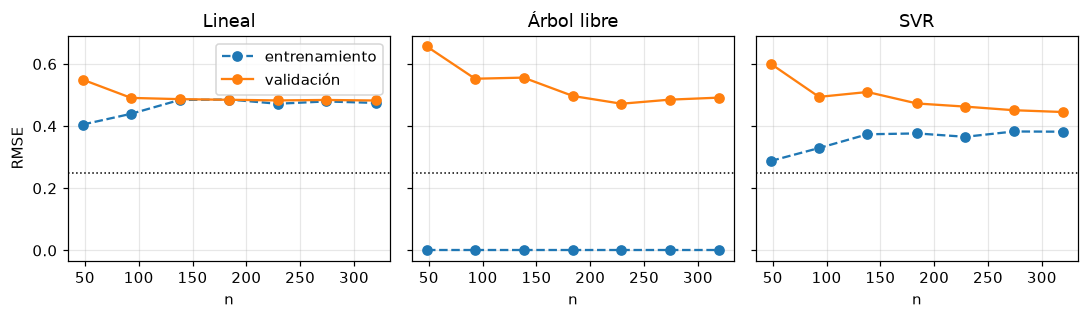

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
candidatos = {"Lineal": finales["Lineal"], "Árbol libre": DecisionTreeRegressor(random_state=0), "SVR": finales["SVR"]}
for ax, (nom, est) in zip(axs, candidatos.items()):
    ns, tr, va = learning_curve(est, Xtr, ytr, train_sizes=np.linspace(0.15, 1, 7), cv=kf, scoring=SCORE, n_jobs=1)
    ax.plot(ns, -tr.mean(axis=1), "o--", label="entrenamiento"); ax.plot(ns, -va.mean(axis=1), "o-", label="validación")
    ax.axhline(SIGMA, color="k", ls=":", lw=1); ax.set_title(nom); ax.set_xlabel("n")
axs[0].set_ylabel("RMSE"); axs[0].legend(); plt.tight_layout(); plt.show()

✏️ **Pregunta 7.2.** Describe en una frase cada panel: ¿qué indica la brecha (o su ausencia) y qué pasaría si consiguieras **más datos**? ¿Ayudaría a cada modelo?

**Respuesta:** En el modelo lineal las curvas quedan juntas pero en un error alto, señal de sesgo; más datos ayudarían poco. En el árbol libre aparece una brecha grande, señal de varianza; más datos sí pueden reducirla. En SVR las curvas se acercan a un error bajo, por lo que más datos podrían aportar una mejora menor y más estable.

### Entregable: tabla del informe

Escribe un **comentario propio** (una frase) para cada modelo y guarda la tabla en `entregable_unidad7.csv`.

In [16]:
comentarios = {
    "Lineal": "Presenta sesgo alto porque no capta la relación no lineal.",
    "Polinomial": "Capta la curvatura, aunque su flexibilidad aumenta la variación.",
    "Ridge": "Regulariza el polinomio y estabiliza sus coeficientes.",
    "Lasso": "Reduce coeficientes y conserva un ajuste compacto.",
    "Elastic Net": "Combina las dos penalizaciones y mantiene estabilidad.",
    "SVR": "Logra un ajuste no lineal estable después del escalado.",
    "Árbol": "Es interpretable, pero resulta sensible a las muestras de entrenamiento.",
}
salida = informe.reset_index()[["modelo", "hiperparametros", "rmse_cv_anidada", "rmse_cv_anidada_sd", "rmse_entrenamiento", "rmse_prueba", "diagnostico"]].copy()
salida["comentario"] = salida["modelo"].map(comentarios)
salida.to_csv("entregable_unidad7.csv", index=False, encoding="utf-8")
print(salida.to_string(index=False))

     modelo                           hiperparametros  rmse_cv_anidada  rmse_cv_anidada_sd  rmse_entrenamiento  rmse_prueba   diagnostico                                                               comentario
      Árbol   {'max_depth': 8, 'min_samples_leaf': 5}            0.446               0.062               0.244        0.429 varianza alta Es interpretable, pero resulta sensible a las muestras de entrenamiento.
        SVR {'C': 100, 'epsilon': 0.2, 'gamma': 0.01}            0.450               0.020               0.386        0.449    sesgo alto                  Logra un ajuste no lineal estable después del escalado.
 Polinomial                             {'degree': 2}            0.462               0.034               0.408        0.439    sesgo alto         Capta la curvatura, aunque su flexibilidad aumenta la variación.
Elastic Net          {'alpha': 0.01, 'l1_ratio': 0.8}            0.464               0.025               0.419        0.451    sesgo alto                   

## Parte 8 — Recomendación final

Tu jefa necesita un modelo para estimar precios de viviendas y quiere saber **cuál usar y cuánto confiar en él**.

✏️ **Pregunta 8.1.** En **6 a 8 líneas** recomienda un modelo: (1) cuál y con qué hiperparámetros; (2) cómo lo evaluaste (qué validación, por qué anidada); (3) desempeño esperado con cifras (RMSE en cientos de miles de pesos y frente al piso de 0.25); (4) por qué ganó en términos de sesgo y varianza; (5) límites (datos simulados, un solo conjunto, qué no sabemos) y cuidados al usarlo (extrapolación, reentrenar).

**Respuesta:**  
Recomiendo el árbol con `max_depth=8` y `min_samples_leaf=5`.  
Lo evalué con validación cruzada anidada para separar el ajuste de la medición.  
Su RMSE esperado es 0.446 ± 0.062, frente al piso de ruido de 0.25.  
En prueba obtuvo 0.429, equivalente a unos 42 900 pesos.  
Su sesgo es bajo, aunque la varianza es mayor que la de SVR.  
La diferencia de 0.004 frente a SVR no supera la dispersión, así que ambos son defendibles.  
Los datos son simulados. En uso real revisaría extrapolación, cambios de distribución y reentrenamiento.

## Parte 9 — Reto (5 puntos de bonificación)

*Presentación B7.* Los árboles **no necesitan estandarizar**. Compruébalo: ajusta el mismo árbol (misma `random_state`) **con** y **sin** `StandardScaler` y compara sus predicciones en prueba. Después haz lo mismo con **SVR**.

In [17]:
a_sin = DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=0).fit(Xtr, ytr)
a_con = make_pipeline(StandardScaler(), DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=0)).fit(Xtr, ytr)
print("Árbol: diferencia máxima entre predicciones =", float(np.abs(a_sin.predict(Xte) - a_con.predict(Xte)).max()))

s_sin = SVR(C=10, gamma=0.05).fit(Xtr, ytr)
s_con = make_pipeline(StandardScaler(), SVR(C=10, gamma=0.05)).fit(Xtr, ytr)
print(f"SVR  : RMSE prueba sin escalar = {rmse(s_sin, Xte, yte):.3f}    con escalado = {rmse(s_con, Xte, yte):.3f}")

Árbol: diferencia máxima entre predicciones = 0.0
SVR  : RMSE prueba sin escalar = 0.829    con escalado = 0.450


✏️ **Pregunta del reto.** ¿Por qué el árbol da exactamente las mismas predicciones con y sin escalado, mientras que el SVR cambia? ¿Qué operación hace cada modelo con los valores de las variables?

**Respuesta:** El árbol ordena los valores y decide cortes del tipo variable menor o igual que un umbral. Un escalado monótono conserva ese orden, por eso produce las mismas particiones. SVR usa distancias y productos entre observaciones. Cambiar la escala modifica esas distancias, el efecto de `gamma` y la forma de la función ajustada.